# Hidden Query: Pixel vs Encoder Memorization Probe

This notebook does one explicit, auditable experiment:

1. load `N` reference images and `M` query images;
2. hide one chosen query image inside the reference bank at a known index;
3. compute nearest-neighbor `d1`, `d2`, `d1/d2`, nearest-neighbor index, and `f_mem` in raw pixel space;
4. repeat the same computation in encoder feature space with `inception-v3-compat`;
5. check whether the inserted reference slot is recovered.

There are no notebook helper functions below. The metric math is written directly in cells so the control flow stays easy to inspect.

## 0. Knobs

In [12]:
DATA_ROOT = "../data"
USE_TRAIN_SPLIT = False

N_REFERENCE = 32
M_QUERY = 4
HIDDEN_QUERY_ROW = 1
HIDDEN_REF_SLOT = 7

RHO = 0.5
SEED = 0

ENCODER_NAME = "inception-v3-compat"
ENCODER_IMAGE_SIZE = 299
ENCODER_BATCH = 8

## 1. Imports

In [13]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import torch
import torch.nn.functional as F
from torch_fidelity.utils import create_feature_extractor, resolve_feature_layer_for_metric
from torchvision import datasets

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(SEED)

print("device:", DEVICE)
print("cwd:", Path.cwd())

device: cuda
cwd: /proj/rep-learning-robotics/users/x_moalj/project_mem_par/mem_par/notebooks


## 2. Load `N` Reference Images And `M` Query Images

In [14]:
assert 0 <= HIDDEN_QUERY_ROW < M_QUERY
assert 0 <= HIDDEN_REF_SLOT < N_REFERENCE

mnist = datasets.MNIST(root=DATA_ROOT, train=USE_TRAIN_SPLIT, download=False)
all_images = mnist.data.float().div(255.0)
all_labels = mnist.targets.clone()

perm = torch.randperm(len(all_images), generator=torch.Generator().manual_seed(SEED))
reference_idx = perm[:N_REFERENCE]
query_idx = perm[N_REFERENCE:N_REFERENCE + M_QUERY]

reference_clean = all_images[reference_idx].unsqueeze(1)
reference_labels = all_labels[reference_idx]
query_images = all_images[query_idx].unsqueeze(1)
query_labels = all_labels[query_idx]

hidden_query = query_images[HIDDEN_QUERY_ROW:HIDDEN_QUERY_ROW + 1].clone()
hidden_query_label = int(query_labels[HIDDEN_QUERY_ROW].item())
hidden_query_dataset_index = int(query_idx[HIDDEN_QUERY_ROW].item())

reference_with_hidden = reference_clean.clone()
reference_with_hidden[HIDDEN_REF_SLOT] = hidden_query[0]

print("reference bank shape:", tuple(reference_with_hidden.shape))
print("query bank shape:", tuple(query_images.shape))
print("hidden query row:", HIDDEN_QUERY_ROW)
print("hidden query label:", hidden_query_label)
print("hidden query original dataset index:", hidden_query_dataset_index)
print("hidden reference slot:", HIDDEN_REF_SLOT)

reference bank shape: (32, 1, 28, 28)
query bank shape: (4, 1, 28, 28)
hidden query row: 1
hidden query label: 8
hidden query original dataset index: 1899
hidden reference slot: 7


## 3. Visual Sanity Check

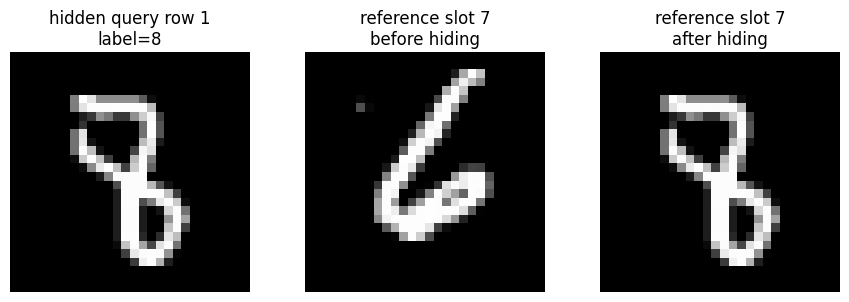

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(9, 3))

axes[0].imshow(hidden_query[0, 0], cmap="gray")
axes[0].set_title(f"hidden query row {HIDDEN_QUERY_ROW}\nlabel={hidden_query_label}")
axes[0].axis("off")

axes[1].imshow(reference_clean[HIDDEN_REF_SLOT, 0], cmap="gray")
axes[1].set_title(f"reference slot {HIDDEN_REF_SLOT}\nbefore hiding")
axes[1].axis("off")

axes[2].imshow(reference_with_hidden[HIDDEN_REF_SLOT, 0], cmap="gray")
axes[2].set_title(f"reference slot {HIDDEN_REF_SLOT}\nafter hiding")
axes[2].axis("off")

plt.tight_layout()

## 4. Math Setup

Let

- $R = \{r_j\}_{j=1}^{N}$ be the reference bank,
- $Q = \{q_i\}_{i=1}^{M}$ be the query bank,
- $i^\star$ be the chosen hidden query row,
- $j^\star$ be the reference slot where we hide $q_{i^\star}$,
- $\widetilde{R} = \{\tilde r_j\}_{j=1}^{N}$ be the modified reference bank after inserting the hidden query.

In raw pixel space we flatten each image and form the distance matrix

$$
D_{ij}^{\mathrm{pix}} = \left\|\operatorname{vec}(q_i) - \operatorname{vec}(\tilde r_j)\right\|_2.
$$

In encoder space we first embed each image with a feature map $\phi(\cdot)$ and then compute

$$
D_{ij}^{\mathrm{enc}} = \left\|\phi(q_i) - \phi(\tilde r_j)\right\|_2.
$$

For each query row $i$, let $d_{1,i}$ and $d_{2,i}$ be the smallest and second-smallest entries in the corresponding row of the distance matrix. The nearest-neighbor ratio is

$$
\rho_i = \frac{d_{1,i}}{d_{2,i}}.
$$

Using the threshold $\tau = \texttt{RHO}$, the memorization fraction is

$$
f_{\mathrm{mem}}(\tau) = \frac{1}{M}\sum_{i=1}^{M} \mathbf{1}\left[\rho_i < \tau\right].
$$

The concrete recovery question in this notebook is whether the hidden row $i^\star$ returns nearest-neighbor index $j^\star$ in both $D^{\mathrm{pix}}$ and $D^{\mathrm{enc}}$.

## 5. Raw Pixel Space: $D^{\mathrm{pix}}$, $d_1$, $d_2$, $d_1/d_2$, $f_{\mathrm{mem}}$, And NN Index

In [17]:
pixel_query = query_images.flatten(1)
pixel_reference_clean = reference_clean.flatten(1)
pixel_reference_hidden = reference_with_hidden.flatten(1)

pixel_clean_dist = torch.cdist(pixel_query, pixel_reference_clean)
pixel_hidden_dist = torch.cdist(pixel_query, pixel_reference_hidden)

pixel_clean_top2 = torch.topk(pixel_clean_dist, k=2, largest=False, dim=1)
pixel_hidden_top2 = torch.topk(pixel_hidden_dist, k=2, largest=False, dim=1)

pixel_clean_d1 = pixel_clean_top2.values[:, 0]
pixel_clean_d2 = pixel_clean_top2.values[:, 1]
pixel_hidden_d1 = pixel_hidden_top2.values[:, 0]
pixel_hidden_d2 = pixel_hidden_top2.values[:, 1]

pixel_clean_ratio = pixel_clean_d1 / pixel_clean_d2.clamp(min=1.0e-12)
pixel_hidden_ratio = pixel_hidden_d1 / pixel_hidden_d2.clamp(min=1.0e-12)

pixel_clean_nn = pixel_clean_top2.indices[:, 0]
pixel_hidden_nn = pixel_hidden_top2.indices[:, 0]

pixel_clean_f_mem = float((pixel_clean_ratio < RHO).float().mean().item())
pixel_hidden_f_mem = float((pixel_hidden_ratio < RHO).float().mean().item())

pixel_table = pd.DataFrame({
    "query_row": list(range(M_QUERY)),
    "query_label": query_labels.tolist(),
    "clean_nn_index": pixel_clean_nn.tolist(),
    "hidden_nn_index": pixel_hidden_nn.tolist(),
    "clean_d1": pixel_clean_d1.tolist(),
    "hidden_d1": pixel_hidden_d1.tolist(),
    "clean_d2": pixel_clean_d2.tolist(),
    "hidden_d2": pixel_hidden_d2.tolist(),
    "clean_ratio_d1d2": pixel_clean_ratio.tolist(),
    "hidden_ratio_d1d2": pixel_hidden_ratio.tolist(),
})
pixel_table["pixel_hit_hidden_slot"] = pixel_table["hidden_nn_index"] == HIDDEN_REF_SLOT
pixel_table["pixel_f_mem_flag"] = pixel_table["hidden_ratio_d1d2"] < RHO

print(f"pixel f_mem before hiding : {pixel_clean_f_mem:.4f}")
print(f"pixel f_mem after hiding  : {pixel_hidden_f_mem:.4f}")
pixel_table

pixel f_mem before hiding : 0.0000
pixel f_mem after hiding  : 0.2500


,query_row,query_label,clean_nn_index,hidden_nn_index,clean_d1,hidden_d1,clean_d2,hidden_d2,clean_ratio_d1d2,hidden_ratio_d1d2,pixel_hit_hidden_slot,pixel_f_mem_flag
0,0,7,18,18,7.890084,7.890084,7.955720,7.955720,0.991750,0.991750,False,False
1,1,8,6,7,6.899806,0.000000,7.193006,6.899806,0.959238,0.000000,True,True
2,2,0,26,26,8.568569,8.568569,8.668970,8.668970,0.988418,0.988418,False,False
3,3,2,7,16,10.218500,10.294515,10.294515,10.401209,0.992616,0.989742,False,False


### Pixel-space `cdist` matrices

In [ ]:
pixel_clean_cdist_df = pd.DataFrame(
    pixel_clean_dist.cpu().numpy(),
    index=[f"q{i}" for i in range(M_QUERY)],
    columns=[f"r{j}" for j in range(N_REFERENCE)],
)

pixel_hidden_cdist_df = pd.DataFrame(
    pixel_hidden_dist.cpu().numpy(),
    index=[f"q{i}" for i in range(M_QUERY)],
    columns=[f"r{j}" for j in range(N_REFERENCE)],
)

print("pixel-space clean cdist matrix")
display(pixel_clean_cdist_df)
print("pixel-space hidden-bank cdist matrix")
display(pixel_hidden_cdist_df)

## 6. Encoder Space: $D^{\mathrm{enc}}$ With `inception-v3-compat`

In [18]:
feature_layer = resolve_feature_layer_for_metric("fid", feature_extractor=ENCODER_NAME)
extractor = create_feature_extractor(
    ENCODER_NAME,
    [feature_layer],
    cuda=DEVICE.startswith("cuda"),
    verbose=False,
)

query_rgb = query_images.repeat(1, 3, 1, 1)
reference_clean_rgb = reference_clean.repeat(1, 3, 1, 1)
reference_hidden_rgb = reference_with_hidden.repeat(1, 3, 1, 1)

query_rgb = F.interpolate(query_rgb, size=(ENCODER_IMAGE_SIZE, ENCODER_IMAGE_SIZE), mode="bilinear", align_corners=False)
reference_clean_rgb = F.interpolate(reference_clean_rgb, size=(ENCODER_IMAGE_SIZE, ENCODER_IMAGE_SIZE), mode="bilinear", align_corners=False)
reference_hidden_rgb = F.interpolate(reference_hidden_rgb, size=(ENCODER_IMAGE_SIZE, ENCODER_IMAGE_SIZE), mode="bilinear", align_corners=False)

query_uint8 = torch.round(query_rgb * 255.0).clamp(0, 255).to(torch.uint8)
reference_clean_uint8 = torch.round(reference_clean_rgb * 255.0).clamp(0, 255).to(torch.uint8)
reference_hidden_uint8 = torch.round(reference_hidden_rgb * 255.0).clamp(0, 255).to(torch.uint8)

query_features = []
for start in range(0, len(query_uint8), ENCODER_BATCH):
    out = extractor(query_uint8[start:start + ENCODER_BATCH].to(DEVICE))
    feats = extractor.convert_features_tuple_to_dict(out)[feature_layer].flatten(1).float().cpu()
    query_features.append(feats)
query_features = torch.cat(query_features, dim=0)

reference_clean_features = []
for start in range(0, len(reference_clean_uint8), ENCODER_BATCH):
    out = extractor(reference_clean_uint8[start:start + ENCODER_BATCH].to(DEVICE))
    feats = extractor.convert_features_tuple_to_dict(out)[feature_layer].flatten(1).float().cpu()
    reference_clean_features.append(feats)
reference_clean_features = torch.cat(reference_clean_features, dim=0)

reference_hidden_features = []
for start in range(0, len(reference_hidden_uint8), ENCODER_BATCH):
    out = extractor(reference_hidden_uint8[start:start + ENCODER_BATCH].to(DEVICE))
    feats = extractor.convert_features_tuple_to_dict(out)[feature_layer].flatten(1).float().cpu()
    reference_hidden_features.append(feats)
reference_hidden_features = torch.cat(reference_hidden_features, dim=0)

print("feature layer:", feature_layer)
print("query feature shape:", tuple(query_features.shape))
print("reference feature shape:", tuple(reference_hidden_features.shape))

feature layer: 2048
query feature shape: (4, 2048)
reference feature shape: (32, 2048)


In [19]:
encoder_clean_dist = torch.cdist(query_features, reference_clean_features)
encoder_hidden_dist = torch.cdist(query_features, reference_hidden_features)

encoder_clean_top2 = torch.topk(encoder_clean_dist, k=2, largest=False, dim=1)
encoder_hidden_top2 = torch.topk(encoder_hidden_dist, k=2, largest=False, dim=1)

encoder_clean_d1 = encoder_clean_top2.values[:, 0]
encoder_clean_d2 = encoder_clean_top2.values[:, 1]
encoder_hidden_d1 = encoder_hidden_top2.values[:, 0]
encoder_hidden_d2 = encoder_hidden_top2.values[:, 1]

encoder_clean_ratio = encoder_clean_d1 / encoder_clean_d2.clamp(min=1.0e-12)
encoder_hidden_ratio = encoder_hidden_d1 / encoder_hidden_d2.clamp(min=1.0e-12)

encoder_clean_nn = encoder_clean_top2.indices[:, 0]
encoder_hidden_nn = encoder_hidden_top2.indices[:, 0]

encoder_clean_f_mem = float((encoder_clean_ratio < RHO).float().mean().item())
encoder_hidden_f_mem = float((encoder_hidden_ratio < RHO).float().mean().item())

encoder_table = pd.DataFrame({
    "query_row": list(range(M_QUERY)),
    "query_label": query_labels.tolist(),
    "clean_nn_index": encoder_clean_nn.tolist(),
    "hidden_nn_index": encoder_hidden_nn.tolist(),
    "clean_d1": encoder_clean_d1.tolist(),
    "hidden_d1": encoder_hidden_d1.tolist(),
    "clean_d2": encoder_clean_d2.tolist(),
    "hidden_d2": encoder_hidden_d2.tolist(),
    "clean_ratio_d1d2": encoder_clean_ratio.tolist(),
    "hidden_ratio_d1d2": encoder_hidden_ratio.tolist(),
})
encoder_table["encoder_hit_hidden_slot"] = encoder_table["hidden_nn_index"] == HIDDEN_REF_SLOT
encoder_table["encoder_f_mem_flag"] = encoder_table["hidden_ratio_d1d2"] < RHO

print(f"encoder f_mem before hiding : {encoder_clean_f_mem:.4f}")
print(f"encoder f_mem after hiding  : {encoder_hidden_f_mem:.4f}")
encoder_table

encoder f_mem before hiding : 0.0000
encoder f_mem after hiding  : 0.2500


,query_row,query_label,clean_nn_index,hidden_nn_index,clean_d1,hidden_d1,clean_d2,hidden_d2,clean_ratio_d1d2,hidden_ratio_d1d2,encoder_hit_hidden_slot,encoder_f_mem_flag
0,0,7,23,23,11.410169,11.410169,11.916616,11.916616,0.957501,0.957501,False,False
1,1,8,6,7,8.023617,0.011049,9.950325,8.023617,0.806367,0.001377,True,True
2,2,0,10,10,8.567025,8.567025,9.062170,9.062170,0.945361,0.945361,False,False
3,3,2,3,3,10.203391,10.203391,10.325885,10.325885,0.988137,0.988137,False,False


### Encoder-space `cdist` matrices

In [ ]:
encoder_clean_cdist_df = pd.DataFrame(
    encoder_clean_dist.cpu().numpy(),
    index=[f"q{i}" for i in range(M_QUERY)],
    columns=[f"r{j}" for j in range(N_REFERENCE)],
)

encoder_hidden_cdist_df = pd.DataFrame(
    encoder_hidden_dist.cpu().numpy(),
    index=[f"q{i}" for i in range(M_QUERY)],
    columns=[f"r{j}" for j in range(N_REFERENCE)],
)

print("encoder-space clean cdist matrix")
display(encoder_clean_cdist_df)
print("encoder-space hidden-bank cdist matrix")
display(encoder_hidden_cdist_df)

## 7. Final Comparison: Did We Recover $j^\star$?

In [20]:
comparison = pd.DataFrame({
    "query_row": list(range(M_QUERY)),
    "query_label": query_labels.tolist(),
    "pixel_nn_index_after_hiding": pixel_hidden_nn.tolist(),
    "pixel_ratio_d1d2_after_hiding": pixel_hidden_ratio.tolist(),
    "pixel_hit_hidden_slot": (pixel_hidden_nn == HIDDEN_REF_SLOT).tolist(),
    "encoder_nn_index_after_hiding": encoder_hidden_nn.tolist(),
    "encoder_ratio_d1d2_after_hiding": encoder_hidden_ratio.tolist(),
    "encoder_hit_hidden_slot": (encoder_hidden_nn == HIDDEN_REF_SLOT).tolist(),
})

print("target hidden slot:", HIDDEN_REF_SLOT)
print("hidden query row:", HIDDEN_QUERY_ROW)
print()
print("pixel recovered hidden slot:", int(pixel_hidden_nn[HIDDEN_QUERY_ROW].item()) == HIDDEN_REF_SLOT)
print("encoder recovered hidden slot:", int(encoder_hidden_nn[HIDDEN_QUERY_ROW].item()) == HIDDEN_REF_SLOT)
print()
print(f"pixel hidden-row d1       : {float(pixel_hidden_d1[HIDDEN_QUERY_ROW].item()):.6f}")
print(f"pixel hidden-row d1/d2    : {float(pixel_hidden_ratio[HIDDEN_QUERY_ROW].item()):.6f}")
print(f"encoder hidden-row d1     : {float(encoder_hidden_d1[HIDDEN_QUERY_ROW].item()):.6f}")
print(f"encoder hidden-row d1/d2  : {float(encoder_hidden_ratio[HIDDEN_QUERY_ROW].item()):.6f}")
print()
print(f"pixel f_mem after hiding   : {pixel_hidden_f_mem:.4f}")
print(f"encoder f_mem after hiding : {encoder_hidden_f_mem:.4f}")

comparison

target hidden slot: 7
hidden query row: 1

pixel recovered hidden slot: True
encoder recovered hidden slot: True

pixel hidden-row d1       : 0.000000
pixel hidden-row d1/d2    : 0.000000
encoder hidden-row d1     : 0.011049
encoder hidden-row d1/d2  : 0.001377

pixel f_mem after hiding   : 0.2500
encoder f_mem after hiding : 0.2500


,query_row,query_label,pixel_nn_index_after_hiding,pixel_ratio_d1d2_after_hiding,pixel_hit_hidden_slot,encoder_nn_index_after_hiding,encoder_ratio_d1d2_after_hiding,encoder_hit_hidden_slot
0,0,7,18,0.991750,False,23,0.957501,False
1,1,8,7,0.000000,True,7,0.001377,True
2,2,0,26,0.988418,False,10,0.945361,False
3,3,2,16,0.989742,False,3,0.988137,False


If the probe is behaving correctly, the hidden query row should point to `HIDDEN_REF_SLOT` in both spaces, `d1` should collapse to `0`, and the hidden row should become an obvious low-ratio (`d1/d2`) case.